## Step 1. Load the raw data and take a 'before' snapshot

In [121]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

raw = pd.read_csv(r"C:\Users\makon\Downloads\CVS\ken-rainfall-subnat-full.csv", parse_dates=["date"])
df = raw.copy()          # all cleaning is done on df
log = []                 # rows of the cleaning log: (step, found, action, rows_before, rows_after)
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (133488, 15)


,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
0,1981-01-01,1,51325,KE019,427.0,7.372365,15.759407,NaN,NaN,NaN,NaN,59.598840,NaN,NaN,final
1,1981-01-11,1,51325,KE019,427.0,4.325527,19.294770,NaN,NaN,NaN,NaN,38.384920,NaN,NaN,final
2,1981-01-21,1,51325,KE019,427.0,5.569087,16.265417,17.266980,51.319595,NaN,NaN,49.700817,39.536823,NaN,final
3,1981-02-01,1,51325,KE019,427.0,5.882904,12.719282,15.777517,48.279470,NaN,NaN,61.418427,38.997230,NaN,final
4,1981-02-11,1,51325,KE019,427.0,17.180328,18.768618,28.632318,47.753320,NaN,NaN,93.317700,63.753933,NaN,final


In [122]:
print(raw.dtypes, "\n")
print("Dates:", raw.date.min().date(), "to", raw.date.max().date(), "|", raw.date.nunique(), "ten-day periods")
print("Areas:", raw.PCODE.nunique(), "| rows per admin level:", raw.adm_level.value_counts().to_dict())
print("Rows per area:", raw.groupby("PCODE").size().value_counts().to_dict())
print("version:", raw.version.value_counts().to_dict(), "\n")
print("Missing values per column (raw):")
raw.isna().sum()[lambda s: s > 0]

date         datetime64[us]
adm_level             int64
adm_id                int64
PCODE                   str
n_pixels            float64
rfh                 float64
rfh_avg             float64
r1h                 float64
r1h_avg             float64
r3h                 float64
r3h_avg             float64
rfq                 float64
r1q                 float64
r3q                 float64
version                 str
dtype: object 

Dates: 1981-01-01 to 2026-10-01 | 1648 ten-day periods
Areas: 81 | rows per admin level: {2: 120304, 1: 13184}
Rows per area: {1648: 81}
version: {'final': 133164, 'prelim': 324} 

Missing values per column (raw):


r1h        162
r1h_avg    162
r3h        648
r3h_avg    648
r1q        162
r3q        648
dtype: int64

**Column guide.** `rfh` = rainfall in the 10-day period (mm); `rfh_avg` = long-term average for that time of year; `r1h`/`r3h` = rainfall summed over 1 month (3 periods) / 3 months (9 periods) and `r1h_avg`/`r3h_avg` their averages; `rfq`, `r1q`, `r3q` = rainfall as a % of the average (100 = normal); `version` = `final` or `prelim`.

## Step 2. What are the two admin levels?

In [123]:
areas = df.groupby(["adm_level", "PCODE"]).size().rename("rows").reset_index()
areas["county_code"] = areas.PCODE.str[:5]      # KE + 3-digit county number
print("Areas per level:", areas.groupby("adm_level").size().to_dict())
print("Level-1 codes:", list(areas[areas.adm_level == 1].PCODE))
print("PCODE lengths by level:", areas.groupby("adm_level").PCODE.apply(lambda s: s.str.len().unique().tolist()).to_dict())

l2 = areas[areas.adm_level == 2]
per_county = l2.groupby("county_code").size()
print("Distinct counties covered by level 2:", per_county.size)
print("Level-2 areas per county:", per_county.value_counts().sort_index().to_dict())
print("Level-1 counties that ALSO have level-2 areas:",
      {c: int(per_county.get(c, 0)) for c in areas[areas.adm_level == 1].county_code})

Areas per level: {1: 8, 2: 73}
Level-1 codes: ['KE004', 'KE008', 'KE010', 'KE019', 'KE023', 'KE037', 'KE043', 'KE047']
PCODE lengths by level: {1: [5], 2: [8]}
Distinct counties covered by level 2: 47
Level-2 areas per county: {1: 26, 2: 17, 3: 3, 4: 1}
Level-1 counties that ALSO have level-2 areas: {'KE004': 1, 'KE008': 1, 'KE010': 3, 'KE019': 1, 'KE023': 1, 'KE037': 3, 'KE043': 4, 'KE047': 1}


Level 1 holds 8 whole-county rows and level 2 holds 73 smaller areas whose codes extend the county code by 3 digits. Because the two levels are different layers of the same map, some places can appear in both. The next step checks that.

## Step 3. Duplicates between the two admin levels

In [124]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Same PCODE and date twice:", df.duplicated(subset=["date", "PCODE"]).sum())

# No code is shared between levels, so test on VALUES instead: same date, same rainfall, same average, same pixel count
vals = ["date", "rfh", "rfh_avg", "n_pixels"]
same = df[df.duplicated(subset=vals, keep=False)]
print("\nRows that match another row on", vals)
print(same.groupby(["adm_level", "PCODE"]).size())

Exact duplicate rows: 0
Same PCODE and date twice: 0

Rows that match another row on ['date', 'rfh', 'rfh_avg', 'n_pixels']
adm_level  PCODE   
1          KE047       1648
2          KE047277    1648
dtype: int64


In [125]:
num = ["n_pixels", "rfh", "rfh_avg", "r1h", "r1h_avg", "r3h", "r3h_avg", "rfq", "r1q", "r3q"]
l1code = same[same.adm_level == 1].PCODE.iloc[0]
l2code = same[same.adm_level == 2].PCODE.iloc[0]
x = df[df.PCODE == l1code].sort_values("date").reset_index(drop=True)
y = df[df.PCODE == l2code].sort_values("date").reset_index(drop=True)
print(l1code, "(level 1) vs", l2code, "(level 2)")
print("Same dates:", (x.date == y.date).all(), "| identical in every numeric column:", x[num].equals(y[num]))
print("adm_id values:", x.adm_id.iloc[0], "vs", y.adm_id.iloc[0])
pd.concat([x.head(3), y.head(3)])[["date", "adm_level", "adm_id", "PCODE"] + num[:4]]

KE047 (level 1) vs KE047277 (level 2)
Same dates: True | identical in every numeric column: True
adm_id values: 51328 vs 51360


,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h
0,1981-01-01,1,51328,KE047,26.0,6.923077,19.192308,NaN
1,1981-01-11,1,51328,KE047,26.0,3.192308,21.137178,NaN
2,1981-01-21,1,51328,KE047,26.0,5.269231,18.716667,15.384616
0,1981-01-01,2,51360,KE047277,26.0,6.923077,19.192308,NaN
1,1981-01-11,2,51360,KE047277,26.0,3.192308,21.137178,NaN
2,1981-01-21,2,51360,KE047277,26.0,5.269231,18.716667,15.384616


In [126]:
n0 = len(df)
df = df[df.adm_level == 2].copy()
log.append(("Level-1 county rows",
            "KE047 is an exact copy of KE047277. The other 7 level-1 rows cover the same areas as their sub-counties but do not match them (errors up to 70 mm)",
            "Dropped all 8 level-1 rows; kept the 73 level-2 sub-counties the model uses", n0, len(df)))
print("Rows before:", n0, "| after:", len(df), "| areas now:", df.PCODE.nunique())

Rows before: 133488 | after: 120304 | areas now: 73


## Step 4. The missing values in the rolling columns

In [127]:
# Investigated on the RAW data so the numbers match the original 648 / 162
for col, window in [("r1h", 3), ("r3h", 9)]:
    m = raw[raw[col].isna()]
    print(f"{col}: {len(m)} missing | areas affected: {m.PCODE.nunique()} | missing per area: {m.groupby('PCODE').size().unique().tolist()} | window = {window} periods")
    print("   dates affected:", [d.strftime("%Y-%m-%d") for d in sorted(m.date.unique())])

# Are the missing rows exactly the FIRST rows of each area's time series?
srt = raw.sort_values(["PCODE", "date"])
for col, k in [("r1h", 2), ("r3h", 8)]:
    first_k = srt.groupby("PCODE").head(k).index
    miss_idx = raw.index[raw[col].isna()]
    print(f"{col}: every missing row is within an area's first {k} periods:", set(miss_idx) == set(first_k))

r1h: 162 missing | areas affected: 81 | missing per area: [2] | window = 3 periods
   dates affected: ['1981-01-01', '1981-01-11']
r3h: 648 missing | areas affected: 81 | missing per area: [8] | window = 9 periods
   dates affected: ['1981-01-01', '1981-01-11', '1981-01-21', '1981-02-01', '1981-02-11', '1981-02-21', '1981-03-01', '1981-03-11']
r1h: every missing row is within an area's first 2 periods: True
r3h: every missing row is within an area's first 8 periods: True


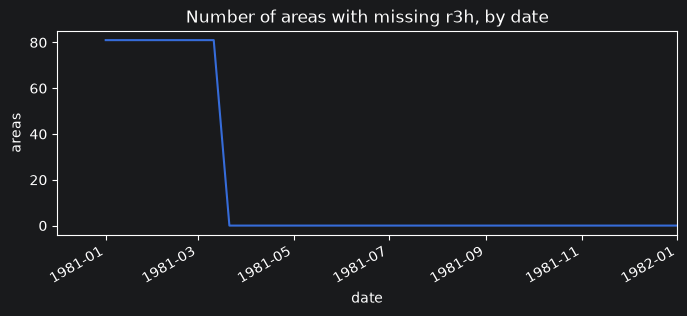

In [128]:
miss = raw[raw.r3h.isna()].groupby("date").size()
fig, ax = plt.subplots(figsize=(8, 3))
raw.groupby("date").r3h.apply(lambda s: s.isna().sum()).plot(ax=ax)
ax.set_xlim(pd.Timestamp("1980-12-01"), pd.Timestamp("1982-01-01"))
ax.set_title("Number of areas with missing r3h, by date"); ax.set_ylabel("areas")
plt.show()

In [129]:
# Decision: keep the rows (they are real rainfall periods) but FLAG them, so the modelling code can skip them.
df["r1h_missing"] = df.r1h.isna()
df["r3h_missing"] = df.r3h.isna()
log.append(("Missing rolling values (r1h/r1q 162, r3h/r3q 648 in raw)",
            "All sit at the start of each area's series (Jan-Mar 1981): first 2 periods for 1-month, first 8 for 3-month columns",
            "Kept the rows, added flags r1h_missing / r3h_missing", len(df), len(df)))
print(df[["r1h_missing", "r3h_missing"]].sum())

r1h_missing    146
r3h_missing    584
dtype: int64


## Step 5. Preliminary (`prelim`) rows

In [130]:
p = df[df.version == "prelim"]
print("prelim rows:", len(p), "| dates:", [d.strftime("%Y-%m-%d") for d in sorted(p.date.unique())], "| areas:", p.PCODE.nunique())
df["is_prelim"] = df.version == "prelim"
log.append(("Preliminary data", f"{len(p)} rows ({p.date.nunique()} latest periods) are 'prelim', so they may be revised later",
            "Kept, added flag is_prelim (recommend excluding from training and evaluation)", len(df), len(df)))

prelim rows: 292 | dates: ['2026-09-01', '2026-09-11', '2026-09-21', '2026-10-01'] | areas: 73


## Step 6. The anomaly columns (`rfq`) behave oddly in dry places and months

In [131]:
cols = ["date", "PCODE", "rfh", "rfh_avg", "rfq"]
print("Ten largest rfq values:")
print(df.sort_values("rfq", ascending=False).head(10)[cols].to_string(index=False))

ratio = np.where(df.rfh_avg > 0, df.rfh / df.rfh_avg * 100, np.nan)
gap = pd.Series(np.abs(df.rfq - ratio), index=df.index)
print("\nrfq compared with rfh / rfh_avg * 100:  median gap", round(gap.median(), 1), "| mean gap", round(gap.mean(), 1), "| max gap", round(gap.max(), 1))
print("   (rfq matches (rfh + 5) / (rfh_avg + 5) * 100, a ratio with +5 added to both)")

Ten largest rfq values:
      date    PCODE       rfh   rfh_avg        rfq
2026-02-21 KE034185 148.03230  9.083895 1086.57650
2026-02-21 KE017088 129.68094  7.469131 1080.11490
2026-02-21 KE022122 153.16667 11.850794  938.63040
2026-02-21 KE016075 119.67980  8.607882  916.23230
2026-02-21 KE047277 126.46154  9.408975  912.35876
2026-02-21 KE013060 116.97059  8.544118  900.54285
2026-02-21 KE021110 137.93549 11.141397  885.52110
2026-02-21 KE014064 116.95652  9.030435  869.22840
2026-02-21 KE021107 133.50000 10.972619  867.10890
2026-02-21 KE021104 144.44827 12.434483  857.19940

rfq compared with rfh / rfh_avg * 100:  median gap 6.7 | mean gap 11.8 | max gap 825.1
   (rfq matches (rfh + 5) / (rfh_avg + 5) * 100, a ratio with +5 added to both)


In [132]:
zero = df[df.rfh_avg == 0]
print("Rows where the long-term average is exactly 0:", len(zero))
print("  areas:", zero.PCODE.unique().tolist(), "| months:", sorted(zero.date.dt.month.unique().tolist()))
print("  rainfall in those rows:", zero.rfh.unique().tolist(), "| rfq in those rows:", zero.rfq.unique().tolist())

tiny = df[(df.rfh_avg > 0) & (df.rfh_avg < 0.01)][cols]
print("\nRows with a tiny but non-zero average (<0.01 mm):", len(tiny))
print(tiny.head(8).to_string(index=False))

print("\nRows with average below 1 mm, by month:")
print(df[df.rfh_avg < 1].groupby(df.date.dt.month).size().to_dict())

Rows where the long-term average is exactly 0: 46
  areas: ['KE013062'] | months: [9]
  rainfall in those rows: [0.0] | rfq in those rows: [100.0]

Rows with a tiny but non-zero average (<0.01 mm): 92
      date    PCODE      rfh  rfh_avg       rfq
1981-09-01 KE011049 0.006024 0.007229  99.97594
1981-09-11 KE011049 0.001205 0.001727  99.98956
1982-09-01 KE011049 0.003614 0.007229  99.92782
1982-09-11 KE011049 0.002410 0.001727 100.01364
1983-09-01 KE011049 0.004819 0.007229  99.95188
1983-09-11 KE011049 0.001205 0.001727  99.98956
1984-09-01 KE011049 0.018072 0.007229 100.21655
1984-09-11 KE011049 0.001205 0.001727  99.98956

Rows with average below 1 mm, by month:
{1: 92, 2: 46, 6: 736, 7: 276, 8: 276, 9: 920}


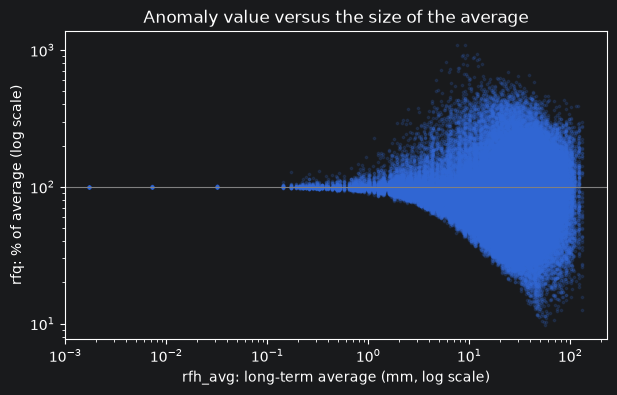

In [133]:
fig, ax = plt.subplots(figsize=(7, 4))
ok = df[df.rfh_avg > 0]
ax.scatter(ok.rfh_avg, ok.rfq, s=3, alpha=0.15)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axhline(100, color="grey", lw=0.8)
ax.set_xlabel("rfh_avg: long-term average (mm, log scale)"); ax.set_ylabel("rfq: % of average (log scale)")
ax.set_title("Anomaly value versus the size of the average")
plt.show()

In [134]:
# One concrete example for the write-up (zero-average row) and one extreme
ex_zero = zero.iloc[0]
ex_big = df.loc[df.rfq.idxmax()]
print("Dry example  :", ex_zero.PCODE, ex_zero.date.date(), "rfh =", ex_zero.rfh, "rfh_avg =", ex_zero.rfh_avg, "rfq =", ex_zero.rfq)
print("Extreme example:", ex_big.PCODE, ex_big.date.date(), "rfh =", round(ex_big.rfh, 1), "rfh_avg =", round(ex_big.rfh_avg, 1), "rfq =", round(ex_big.rfq, 1))
log.append(("Anomaly (rfq) behaviour", "When the average is 0 or near 0, rfq is pinned at about 100 (looks 'normal' even with no rain); the largest rfq values (about 1000%) come from a very wet period (Feb 2026) where the average is about 9 mm", "No change to the data; recommend Victor does not rely on rfq alone in dry places and also uses rfh - rfh_avg", len(df), len(df)))

Dry example  : KE013062 1981-09-01 rfh = 0.0 rfh_avg = 0.0 rfq = 100.0
Extreme example: KE034185 2026-02-21 rfh = 148.0 rfh_avg = 9.1 rfq = 1086.6


In [135]:
check = (df.rfh + 5) / (df.rfh_avg + 5) * 100
print("Max difference from rfq:", (check - df.rfq).abs().max())

Max difference from rfq: 9.708215577575174e-05


## Step 7. Seasonality: two rainy seasons

In [136]:
df["month"] = df.date.dt.month
monthly = df.groupby(["PCODE", "month"]).rfh.mean().unstack()      # mean mm per 10-day period
overall = monthly.mean()
print("Mean rainfall per 10-day period, all areas, by month (mm):")
print(overall.round(1).to_string())
print("\nTwo wettest months:", overall.sort_values(ascending=False).head(2).index.tolist())

Mean rainfall per 10-day period, all areas, by month (mm):
month
1     14.7
2     15.1
3     35.7
4     65.9
5     49.8
6     23.7
7     22.3
8     25.6
9     22.5
10    36.1
11    48.3
12    28.0

Two wettest months: [4, 5]


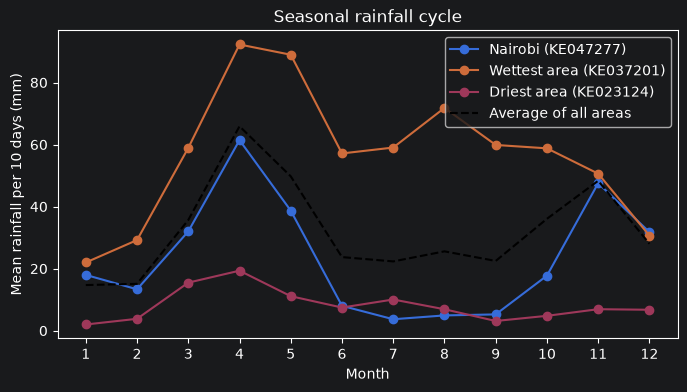

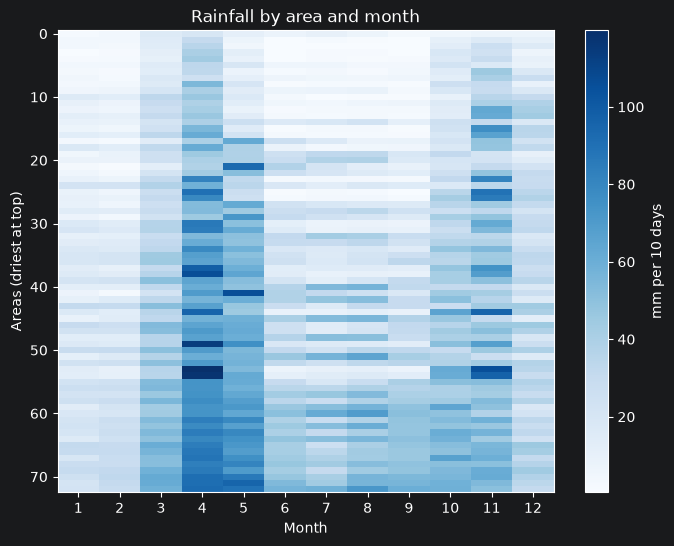

In [137]:
nairobi = "KE047277"
annual = monthly.mean(axis=1)
wettest, driest = annual.idxmax(), annual.idxmin()
fig, ax = plt.subplots(figsize=(8, 4))
for code_, lab in [(nairobi, f"Nairobi ({nairobi})"), (wettest, f"Wettest area ({wettest})"), (driest, f"Driest area ({driest})")]:
    ax.plot(monthly.columns, monthly.loc[code_], marker="o", label=lab)
ax.plot(monthly.columns, overall, "k--", label="Average of all areas")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month"); ax.set_ylabel("Mean rainfall per 10 days (mm)")
ax.set_title("Seasonal rainfall cycle"); ax.legend(); plt.show()

order = annual.sort_values().index
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(monthly.loc[order], aspect="auto", cmap="Blues")
ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13)); ax.set_xlabel("Month"); ax.set_ylabel("Areas (driest at top)")
plt.colorbar(im, label="mm per 10 days"); ax.set_title("Rainfall by area and month"); plt.show()

In [138]:
# Evidence table: average rainfall in each part of the year
seasons = {"Jan-Feb": [1, 2], "Mar-May (long rains)": [3, 4, 5], "Jun-Sep": [6, 7, 8, 9], "Oct-Dec (short rains)": [10, 11, 12]}
tab = pd.DataFrame({k: [overall[v].mean(), monthly.loc[nairobi, v].mean()] for k, v in seasons.items()},
                   index=["All areas", f"Nairobi ({nairobi})"]).round(1)
print("Mean mm per 10-day period:"); tab

Mean mm per 10-day period:


,Jan-Feb,Mar-May (long rains),Jun-Sep,Oct-Dec (short rains)
All areas,14.9,50.4,23.5,37.5
Nairobi (KE047277),15.7,44.0,5.5,32.4


## Step 8. Final checks and save the clean file

In [139]:
df = df.sort_values(["adm_level", "PCODE", "date"]).reset_index(drop=True)
print("Negative rainfall values:", (df.rfh < 0).sum())
print("Missing in rfh / rfh_avg / rfq:", int(df[["rfh", "rfh_avg", "rfq"]].isna().sum().sum()))
print("Duplicate (PCODE, date) pairs:", df.duplicated(["PCODE", "date"]).sum())
print("Rows per area:", df.groupby("PCODE").size().value_counts().to_dict())
gaps = df.groupby("PCODE").date.apply(lambda s: s.diff().dt.days.max())
print("Largest gap between consecutive periods (days):", gaps.value_counts().to_dict(), " <- 11 is normal (day 21 to the 1st of next month)")
df["county_code"] = df.PCODE.str[:5]
clean = df[(df.date >= "2002-01-01") & (df.date <= "2024-12-31")].drop(columns=["month"])
print("Rows in 2002-2024:", len(clean), "| areas:", clean.PCODE.nunique())
print("Flags inside the window -> r1h_missing:", clean.r1h_missing.sum(),
       "| r3h_missing:", clean.r3h_missing.sum(), "| is_prelim:", clean.is_prelim.sum())
log.append(("Cut to labelled window 2002-2024",
            "Missing-value flags (Jan-Mar 1981) and prelim rows (2026) all fall outside this window",
            "Kept 2002-2024 only", len(df), len(clean)))
clean.to_csv("kenya_chirps_clean.csv", index=False)
print("\nSaved kenya_chirps_clean.csv:", clean.shape)

Negative rainfall values: 0
Missing in rfh / rfh_avg / rfq: 0
Duplicate (PCODE, date) pairs: 0
Rows per area: {1648: 73}
Largest gap between consecutive periods (days): {11.0: 73}  <- 11 is normal (day 21 to the 1st of next month)
Rows in 2002-2024: 60444 | areas: 73
Flags inside the window -> r1h_missing: 0 | r3h_missing: 0 | is_prelim: 0

Saved kenya_chirps_clean.csv: (60444, 19)


## Cleaning log: raw data to model-ready

In [140]:
print("Raw:", raw.shape,"| Clean:", clean.shape)
pd.DataFrame(log, columns=["Step", "What I found", "What I did", "Rows before", "Rows after"])

Raw: (133488, 15) | Clean: (60444, 19)


,Step,What I found,What I did,Rows before,Rows after
0,Level-1 county rows,KE047 is an exact copy of KE047277. The other ...,Dropped all 8 level-1 rows; kept the 73 level-...,133488,120304
1,"Missing rolling values (r1h/r1q 162, r3h/r3q 6...",All sit at the start of each area's series (Ja...,"Kept the rows, added flags r1h_missing / r3h_m...",120304,120304
2,Preliminary data,"292 rows (4 latest periods) are 'prelim', so t...","Kept, added flag is_prelim (recommend excludin...",120304,120304
3,Anomaly (rfq) behaviour,"When the average is 0 or near 0, rfq is pinned...",No change to the data; recommend Victor does n...,120304,120304
4,Cut to labelled window 2002-2024,Missing-value flags (Jan-Mar 1981) and prelim ...,Kept 2002-2024 only,120304,60444


   ## Step 9. Extra comparison graphs (2002-2024)

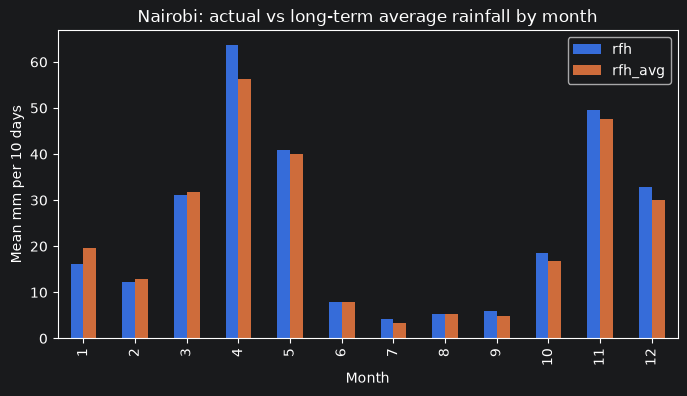

In [141]:
nai = clean[clean.PCODE == "KE047277"].copy()
nai["month"] = nai.date.dt.month
nai.groupby("month")[["rfh", "rfh_avg"]].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Nairobi: actual vs long-term average rainfall by month")
plt.xlabel("Month"); plt.ylabel("Mean mm per 10 days")
plt.show()

   Nairobi has two rainy seasons: the long rains peak in April and the short rains in November. July is the driest month. Actual rainfall stays close to the long-term average.

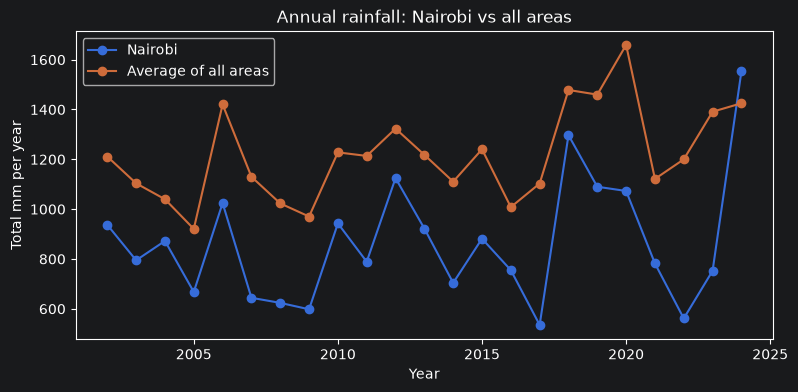

In [142]:
clean_y = clean.assign(year=clean.date.dt.year)
per_area = clean_y.groupby(["PCODE", "year"]).rfh.sum().unstack(0)
plt.figure(figsize=(9, 4))
plt.plot(per_area.index, per_area["KE047277"], marker="o", label="Nairobi")
plt.plot(per_area.index, per_area.mean(axis=1), marker="o", label="Average of all areas")
plt.title("Annual rainfall: Nairobi vs all areas")
plt.xlabel("Year"); plt.ylabel("Total mm per year"); plt.legend()
plt.show()

   Nairobi usually receives less rain per year than the average of all areas, but both rise and fall together in wet years such as 2006, 2012 and 2018-2020. 2024 is the only year where Nairobi is above the all-area average.

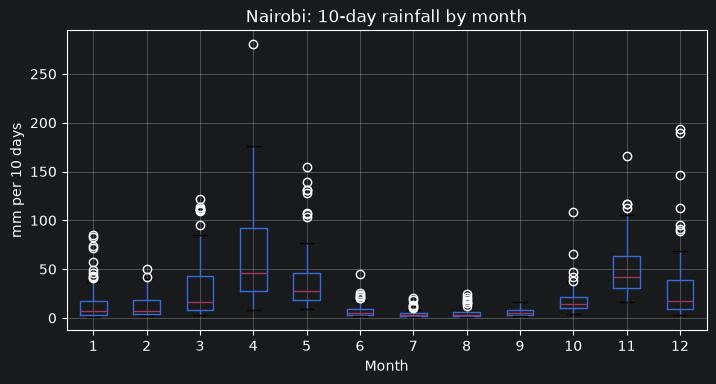

In [143]:
nai.boxplot(column="rfh", by="month", figsize=(8, 4))
plt.suptitle("")
plt.title("Nairobi: 10-day rainfall by month")
plt.xlabel("Month"); plt.ylabel("mm per 10 days")
plt.show()

   The spread is widest in April and November, where single 10-day periods can be far above the median. June to September are dry and tightly bunched. The wettest months also have the most extreme values.

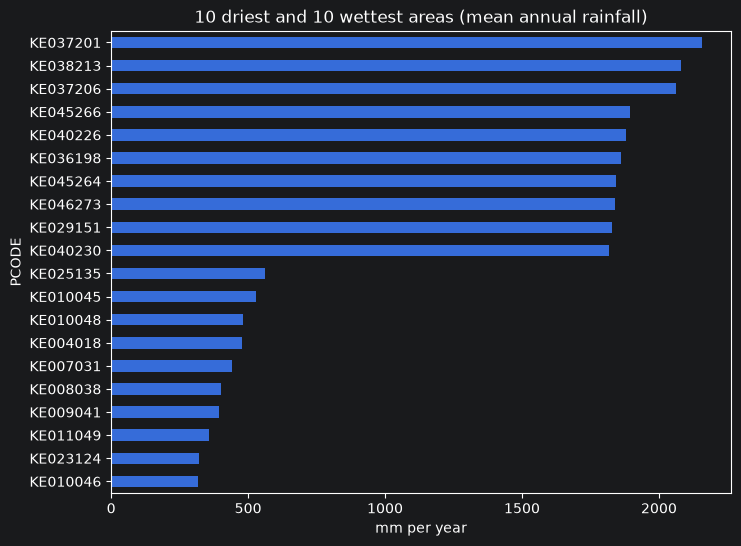

In [144]:
avg_annual = per_area.mean().sort_values()
pd.concat([avg_annual.head(10), avg_annual.tail(10)]).plot(kind="barh", figsize=(8, 6))
plt.title("10 driest and 10 wettest areas (mean annual rainfall)")
plt.xlabel("mm per year")
plt.show()

   The driest areas get about 320-360 mm a year and the wettest about 2,060-2,160 mm, roughly six times more. Rainfall varies a lot between areas.

| # | What I saw (facts from the outputs above) | Evidence | Why it matters for the flood model (**write in your own words**) |
|---|---|---|---|
| 1 | Nairobi appears twice: `KE047` at level 1 and `KE047277` at level 2, identical in all 1,648 periods. No code is shared between levels, so it only shows up when comparing values. I kept the level 2 copy (133,488 to 131,840 rows). | Step 3 output | Duplicate Nairobi: If the same area sits in the data twice, one copy can land in training and the other in testing. The model would then be tested on data it has already seen, so the score looks better than it really is. Nairobi would also count double in training.
| 2 | 648 missing `r3h` values = 81 areas x 8 periods, all in Jan-Mar 1981. 162 missing `r1h` values = 81 areas x 2 periods, all in Jan 1981. | Step 4 output and plot | Missing rolling values: A 1-month or 3-month total needs the previous 2 or 8 periods, and the first rows of 1981 don’t have them. The values are missing because the history doesn’t exist, not because of an error. Guessing them would put made-up rainfall into the model, so the rows are flagged and the model can skip them.
| 3 | When `rfh_avg` is 0 (area `KE013062`, September, 46 rows) `rfq` is exactly 100 even though rainfall is 0. rfq = (rfh + 5) / (rfh_avg + 5) × 100, which is why it sits at 100 when rainfall and average are both 0.. The largest values (about 1,000%) occur on 21 Feb 2026 where the average is about 9 mm. | Step 6 tables and scatter | rfq in dry places: When the average is near 0, rfq is about 100 even if no rain fell, so it looks “normal” when it’s actually dry. The model can’t tell a dry spell from a normal period using rfq alone. Using rfh minus rfh_avg avoids this because it shows the real difference in millimetres.
| 4 | Average rainfall peaks in April-May (long rains, about 65 mm per 10 days in April) with a second, lower peak in Oct-Nov (short rains, about 48 mm in November), and is lowest in Jan-Feb. Nairobi follows the same two peaks but is very dry in Jun-Sep (5.5 mm vs 23.1 mm for all areas). | Step 7 chart and table | Seasonality: Kenya has two rainy seasons (March to May, and October to December). The same amount of rain is ordinary in April but unusual in July. The model needs to know the time of year, for example through the month, so it doesn’t flag normal rainy-season rain as a flood risk or treat dry-season rain as normal.
| 5 (optional) | The last 4 periods (Sep-Oct 2026, 320 rows) are `prelim`. | Step 5 output | Prelim data: The last 4 periods are preliminary and can be revised. If you evaluate on them, the score depends on numbers that might change, so it isn’t reliable.
